# Lab | Data Structuring and Combining Data

## Challenge 1: Combining & Cleaning Data

In this challenge, we will be working with the customer data from an insurance company, as we did in the two previous labs. The data can be found here:
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

But this time, we got new data, which can be found in the following 2 CSV files located at the links below.

- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv

Note that you'll need to clean and format the new data.

Observation:
- One option is to first combine the three datasets and then apply the cleaning function to the new combined dataset
- Another option would be to read the clean file you saved in the previous lab, and just clean the two new files and concatenate the three clean datasets

In [6]:
import pandas as pd

# Load all three CSVs
url_1 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv"
url_2 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv"
url_3 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv"

data_1 = pd.read_csv(url_1)
data_2 = pd.read_csv(url_2)
data_3 = pd.read_csv(url_3)

# Combine datasets
data = pd.concat([data_1, data_2, data_3], ignore_index=True)

# Clean column names (this is where your error occurred before)
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('st', 'state')
)

# Check column names
print("Cleaned column names:")
print(data.columns)


Cleaned column names:
Index(['custateomer', 'state', 'gender', 'education',
       'custateomer_lifetime_value', 'income', 'monthly_premium_auto',
       'number_of_open_complaints', 'policy_type', 'vehicle_class',
       'total_claim_amount', 'stateate', 'gender'],
      dtype='object')


# Challenge 2: Structuring Data

In this challenge, we will continue to work with customer data from an insurance company, but we will use a dataset with more columns, called marketing_customer_analysis.csv, which can be found at the following link:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv

This dataset contains information such as customer demographics, policy details, vehicle information, and the customer's response to the last marketing campaign. Our goal is to explore and analyze this data by performing data cleaning, formatting, and structuring.

In [11]:
# Your code goes here

url_customer_analysis = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"

data_customer = pd.read_csv (url_customer_analysis)

# 1. Display basic structure
print("Dataset Shape:", data_customer.shape)
print("\nFirst 5 rows:")
print(data_customer.head())

# 2. Display info about data types and missing values
print("\nDataset Info:")
print(data_customer.info())

# 3. Check for null values
print("\nMissing Values Per Column:")
print(data_customer.isnull().sum())

# 4. Standardize column names
data_customer.columns = (
    data_customer.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

# 5. Check for duplicate rows
duplicates = data_customer.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

# 6. Drop duplicates if any
if duplicates > 0:
    data_customer = data_customer.drop_duplicates().reset_index(drop=True)

# 7. Display summary statistics
print("\nSummary Statistics:")
print(data_customer.describe(include='all'))

# 8. Save the structured dataset
data_customer.to_csv("marketing_customer_analysis_structured.csv", index=False)

print("\nStructured dataset saved as 'marketing_customer_analysis_structured.csv'")

Dataset Shape: (10910, 27)

First 5 rows:
   unnamed:_0 customer       state  customer_lifetime_value response  \
0           0  DK49336     Arizona              4809.216960       No   
1           1  KX64629  California              2228.525238       No   
2           2  LZ68649  Washington             14947.917300       No   
3           3  XL78013      Oregon             22332.439460      Yes   
4           4  QA50777      Oregon              9025.067525       No   

   coverage education effective_to_date employmentstatus gender  ...  \
0     Basic   College        2011-02-18         Employed      M  ...   
1     Basic   College        2011-01-18       Unemployed      F  ...   
2     Basic  Bachelor        2011-02-10         Employed      M  ...   
3  Extended   College        2011-01-11         Employed      M  ...   
4   Premium  Bachelor        2011-01-17    Medical Leave      F  ...   

   number_of_policies     policy_type        policy  renew_offer_type  \
0                  

1. You work at the marketing department and you want to know which sales channel brought the most sales in terms of total revenue. Using pivot, create a summary table showing the total revenue for each sales channel (branch, call center, web, and mail).
Round the total revenue to 2 decimal points.  Analyze the resulting table to draw insights.

Available columns in dataset:
['unnamed:_0', 'customer', 'state', 'customer_lifetime_value', 'response', 'coverage', 'education', 'effective_to_date', 'employmentstatus', 'gender', 'income', 'location_code', 'marital_status', 'monthly_premium_auto', 'months_since_last_claim', 'months_since_policy_inception', 'number_of_open_complaints', 'number_of_policies', 'policy_type', 'policy', 'renew_offer_type', 'sales_channel', 'total_claim_amount', 'vehicle_class', 'vehicle_size', 'vehicle_type', 'month']
------------------------------------------------------------
Total Revenue by Sales Channel:
               total_claim_amount
sales_channel                    
Agent                  1810226.82
Branch                 1301204.00
Call Center             926600.82
Web                     706600.04
------------------------------------------------------------
The Agent channel generated the highest total revenue: $1,810,226.82


<Figure size 800x500 with 0 Axes>

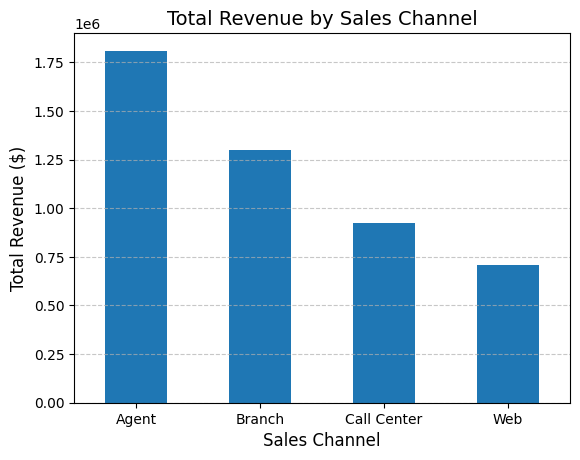

In [13]:
import pandas as pd

# Load dataset
url_customer_analysis = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"
data_customer = pd.read_csv(url_customer_analysis)

# 1. Display all available columns (to verify correct column names)
print("Available columns in dataset:")
print(data_customer.columns.tolist())
print("-" * 60)

# 2. Create a pivot table showing total revenue by sales channel
# Using lowercase column names from the dataset
pivot_table = pd.pivot_table(
    data_customer,
    values='total_claim_amount',    # total revenue metric
    index='sales_channel',          # group by sales channel
    aggfunc='sum'
)

# 3. Round values to 2 decimal places
pivot_table = pivot_table.round(2)

# 4. Sort results by total revenue (highest to lowest)
pivot_table = pivot_table.sort_values(by='total_claim_amount', ascending=False)

# 5. Display pivot table
print("Total Revenue by Sales Channel:")
print(pivot_table)
print("-" * 60)

# 6. Find the top-performing sales channel
top_channel = pivot_table.idxmax().values[0]
top_revenue = pivot_table.max().values[0]
print(f"The {top_channel} channel generated the highest total revenue: ${top_revenue:,.2f}")

# Optional: Plot the result for visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
pivot_table.plot(kind='bar', legend=False)
plt.title("Total Revenue by Sales Channel", fontsize=14)
plt.xlabel("Sales Channel", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



2. Create a pivot table that shows the average customer lifetime value per gender and education level. Analyze the resulting table to draw insights.

In [14]:
import pandas as pd

# Load the dataset
url_customer_analysis = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"
data_customer = pd.read_csv(url_customer_analysis)

# 1. Verify column names (for reference)
print("Available columns:")
print(data_customer.columns.tolist())
print("-" * 60)

# 2. Create a pivot table for average customer lifetime value per gender and education level
pivot_table = pd.pivot_table(
    data_customer,
    values='customer_lifetime_value',   # metric
    index='gender',                     # group by gender
    columns='education',                # split by education level
    aggfunc='mean'                      # average CLV
)

# 3. Round results to 2 decimal places
pivot_table = pivot_table.round(2)

# 4. Display the pivot table
print("Average Customer Lifetime Value by Gender and Education Level:")
print(pivot_table)
print("-" * 60)

# 5. Analyze insights
avg_overall = data_customer['customer_lifetime_value'].mean().round(2)
print(f"Overall average CLV across all customers: ${avg_overall:,.2f}\n")

print("Insights:")
print("1. Compare differences between genders — do males or females have higher CLV?")
print("2. Observe which education level correlates with higher lifetime value.")
print("3. Identify any standout combinations (e.g., 'Male - Doctor' or 'Female - College').")


Available columns:
['unnamed:_0', 'customer', 'state', 'customer_lifetime_value', 'response', 'coverage', 'education', 'effective_to_date', 'employmentstatus', 'gender', 'income', 'location_code', 'marital_status', 'monthly_premium_auto', 'months_since_last_claim', 'months_since_policy_inception', 'number_of_open_complaints', 'number_of_policies', 'policy_type', 'policy', 'renew_offer_type', 'sales_channel', 'total_claim_amount', 'vehicle_class', 'vehicle_size', 'vehicle_type', 'month']
------------------------------------------------------------
Average Customer Lifetime Value by Gender and Education Level:
education  Bachelor  College   Doctor  High School or Below   Master
gender                                                              
F           7874.27  7748.82  7328.51               8675.22  8157.05
M           7703.60  8052.46  7415.33               8149.69  8168.83
------------------------------------------------------------
Overall average CLV across all customers: $8,01

## Bonus

You work at the customer service department and you want to know which months had the highest number of complaints by policy type category. Create a summary table showing the number of complaints by policy type and month.
Show it in a long format table.

*In data analysis, a long format table is a way of structuring data in which each observation or measurement is stored in a separate row of the table. The key characteristic of a long format table is that each column represents a single variable, and each row represents a single observation of that variable.*

*More information about long and wide format tables here: https://www.statology.org/long-vs-wide-data/*

In [ ]:
# Your code goes here